# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     validation_curve, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

df.info()
print(df.shape, df.head(), df.describe(), sep="\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pregnancies     768 non-null    int64  
 1   glucose         768 non-null    int64  
 2   blood_pressure  768 non-null    int64  
 3   skin_thickness  768 non-null    int64  
 4   insulin         768 non-null    int64  
 5   bmi             768 non-null    float64
 6   pedigree        768 non-null    float64
 7   age             768 non-null    int64  
 8   outcome         768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
(768, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66      

In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

Udział:
outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64 

isna: 
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64 

Zera: 
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64


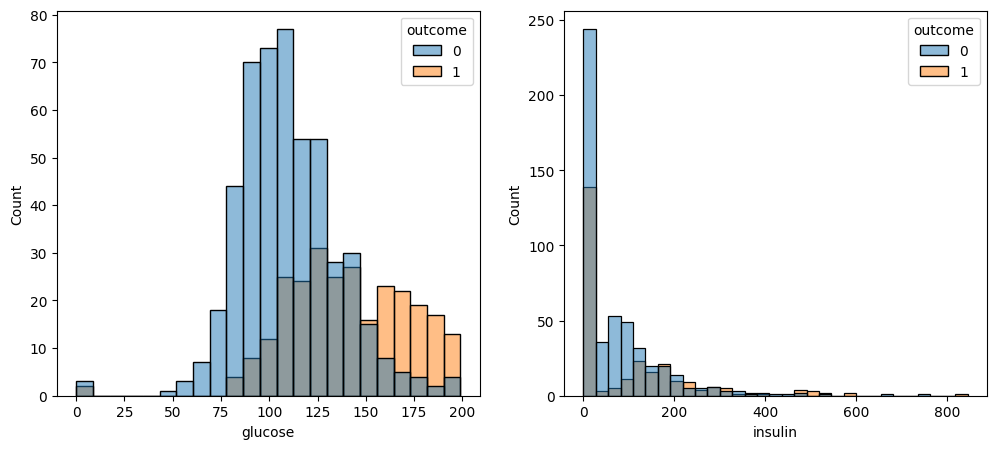

In [3]:
class_share = df["outcome"].value_counts(normalize=True)
print(f"Udział:\n{class_share} \n")

print(f"isna: \n{df.isna().sum()} \n")
zeros = (df == 0).sum()
print(f"Zera: \n{zeros}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])
plt.show()

In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?

 Odp: Jeżeli baseline będzie zawsze 0, accuracy będzię około 0.65.

2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?

Odp: W kolumnach glucose, blood_pressure, skin_thickness, insulin, bmi wartość zero jest niemożliwa. W pregnancies zero jest normalne.

3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

Odp: Glukoza (chociaż żadna cecha nie może jednoznacznie rozróżnić chorych i zdrowych pacjentek (oprócz outcome))

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
df_clean = df.copy()
temp = df[["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]]
df_clean[["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]] = temp.replace(0, np.nan)

print(f"Zera w df_clean: \n{(df_clean==0).sum()}\n")

missing = df_clean.isna().sum()
print(f"Nan w df_clean: \n{missing}\n")



Zera w df_clean: 
pregnancies       111
glucose             0
blood_pressure      0
skin_thickness      0
insulin             0
bmi                 0
pedigree            0
age                 0
outcome           500
dtype: int64

Nan w df_clean: 
pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64



In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Odp: Są kilka możliwości(usunięcie, zamiana na średnią, zamania na medianę ...), ale wybieram jako strategię medianę, bo ze względu na istotny brak danych o insulinie nie można po prostu pominąć połowe danych, warto tylko ich uzupełnić. Wybieram medianę zamiast średniej aby outliery nie wpływały na jakość predykcji.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
features = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age"]

X = df_clean[features]
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

def model_z(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), klasyfikator)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                      CV średnia  CV odch.  train
baseline                   0.651     0.002  0.651
regresja logistyczna       0.778     0.025  0.790
kNN                        0.736     0.021  0.835
drzewo decyzyjne           0.714     0.024  1.000
las losowy                 0.748     0.014  1.000


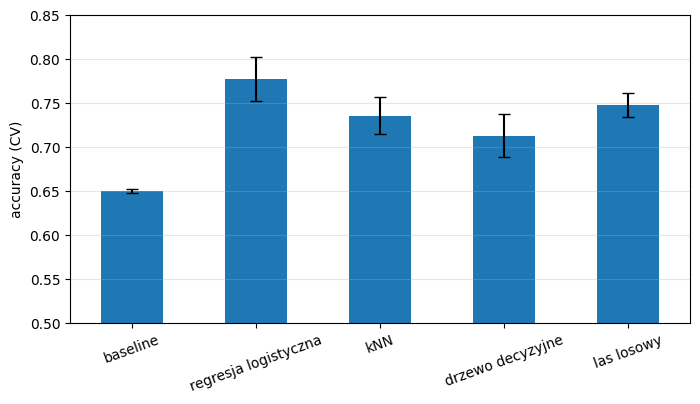

In [9]:
baseline = DummyClassifier(strategy="most_frequent")
regresja_logistyczna = LogisticRegression()
kNN = KNeighborsClassifier()
drzewo_decyzyjne = DecisionTreeClassifier(random_state=42)
las_losowy = RandomForestClassifier(random_state=42)

models = [baseline, regresja_logistyczna, kNN, drzewo_decyzyjne, las_losowy]
model_names = ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]

porownanie = pd.DataFrame(index=model_names, columns=["CV średnia", "CV odch.", "train"])
model_z_i = [model_z(model) for model in models]

for model, name in zip(model_z_i, model_names):
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    porownanie.loc[name, "CV średnia"] = scores.mean()
    porownanie.loc[name, "CV odch."] = scores.std()
    model.fit(X_train, y_train)
    porownanie.loc[name, "train"] = model.score(X_train, y_train)

porownanie = porownanie.astype(float)
print(porownanie.round(3))

ax = porownanie["CV średnia"].plot(kind="bar", yerr=porownanie["CV odch."],
                                   capsize=4, figsize=(8, 4))
ax.set_ylabel("accuracy (CV)")
ax.set_ylim(0.5, 0.85)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20)
plt.show()

In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

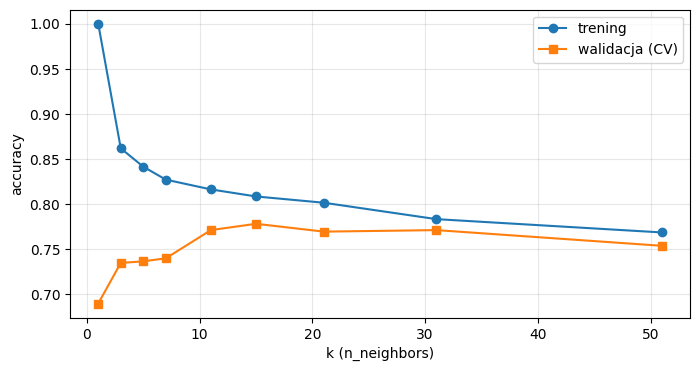

,1,3,5,7,11,15,21,31,51
trening,1.000,0.862,0.841,0.827,0.816,0.808,0.801,0.783,0.768
walidacja,0.689,0.734,0.736,0.740,0.771,0.778,0.769,0.771,0.753


In [11]:
kneighboursclassifier = KNeighborsClassifier()
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

tren, walid = validation_curve(model_z(kneighboursclassifier), X_train, y_train, param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, tren.mean(axis=1), "o-", label="trening")
ax.plot(ks, walid.mean(axis=1), "s-", label="walidacja (CV)")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("accuracy")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({"trening": tren.mean(axis=1), "walidacja": walid.mean(axis=1)}, index=ks).round(3).T

In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

Odp: Dla k = 1 najbliższym sąsiadem każdego punktu treningowego jest on sam (odległość 0), więc model zawsze zwraca jego własną etykietę – wynik treningowy to 1.0. Model zapamiętuje dane zamiast uogólniać.

Przeuczenie – małe k (1–7): duża luka między treningiem (1.0–0.83) a walidacją (0.69–0.74).

Niedouczenie – duże k (51): spada zarówno wynik treningowy (0.768), jak i walidacyjny (0.753); granica decyzyjna jest zbyt wygładzona, model zbliża się do przewidywania klasy większościowej.

Optymalne wartośći leżą pośrodku, ok. k = 15.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                        {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                  {"randomforestclassifier__max_depth": [3, 5, 8, None],
                   "randomforestclassifier__n_estimators": [100, 300]})
    }

wyniki_gs = {}
for name, (model, siatka) in siatki.items():
    gs = GridSearchCV(model_z(model), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[name] = gs
    print(f"{name:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f}")

regresja logistyczna   najlepsze: {'logisticregression__C': 1}  CV = 0.778
kNN                    najlepsze: {'kneighborsclassifier__n_neighbors': 15}  CV = 0.778
drzewo decyzyjne       najlepsze: {'decisiontreeclassifier__max_depth': 5}  CV = 0.750
las losowy             najlepsze: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}  CV = 0.762


In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy: regresja logistyczna  CV = 0.778
Accuracy na zbiorze testowym: 0.724


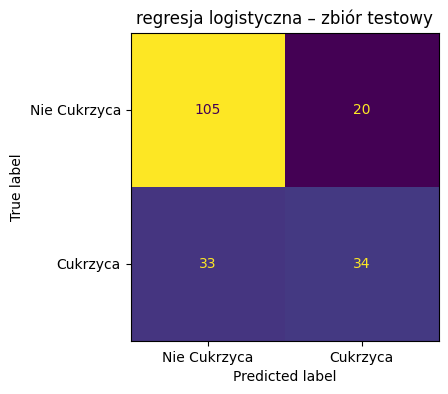

              precision    recall  f1-score   support

Nie Cukrzyca      0.761     0.840     0.798       125
    Cukrzyca      0.630     0.507     0.562        67

    accuracy                          0.724       192
   macro avg      0.695     0.674     0.680       192
weighted avg      0.715     0.724     0.716       192



In [15]:
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

acc_test = model_koncowy.score(X_test, y_test)
print(f"Najlepszy: {najlepszy}  CV = {wyniki_gs[najlepszy].best_score_:.3f}")
print(f"Accuracy na zbiorze testowym: {acc_test:.3f}")

y_pred = model_koncowy.predict(X_test)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Nie Cukrzyca", "Cukrzyca"]).plot(ax=ax, colorbar=False)
ax.set_title(f"{najlepszy} – zbiór testowy")
plt.show()
print(classification_report(y_test, y_pred, target_names=["Nie Cukrzyca", "Cukrzyca"], digits=3))


In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)

Odp: Accuracy na zbiorze testowym wynosi 0.724, a szacunek CV 0.778, czyli test jest niższy o ok. 5.4 p.p. Jedna pacjentka to 1/192 ≈ 0.52 p.p., więc różnica to ok. 10 osób. Nie jest to bardzo niepokojące: przy 192 próbkach błąd standardowy accuracy wynosi ok. √(0.75·0.25/192) ≈ 3 p.p., więc różnica mieści się w granicach losowego rozrzutu (~2 błędy standardowe). Dodatkowo best_score_ jest lekko optymistyczny, bo wybieraliśmy maksimum spośród wielu modeli i parametrów. Ważne, że zbiór testowy nie był używany do wyboru modelu, więc 0.724 to uczciwa ocena.

2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?

Odp: Recall dla klasy „cukrzyca” wynosi 0.507: model wykrywa tylko ok. połowę chorych (34 z 67), a 33 chore pacjentki klasyfikuje jako zdrowe (FN). W diagnostyce to poważny problem, bo przeoczenie choroby kosztuje znacznie więcej niż FP. Accuracy nie jest dobrą metryką wyboru modelu w tym zastosowaniu: klasy są niezbalansowane (sam baseline daje 65%), a koszty błędów są asymetryczne. Lepsze byłyby recall, F1, balanced accuracy lub ROC AUC; można też obniżyć próg decyzyjny, żeby zwiększyć recall kosztem precision.

3. Modele w czołówce różnią się w CV o 1-2 p.p., a odchylenia wynoszą ok. 2-3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

Odp: Nie. Różnice 1-2 p.p. są mniejsze niż odchylenie standardowe między foldami (2-3 p.p.), więc mieszczą się w szumie: regresja logistyczna i kNN mają nawet identyczne CV = 0.778. Przy innym random_state podziału na foldy kolejność mogłaby się zmienić. Można jedynie powiedzieć, że regresja logistyczna, kNN i las losowy są porównywalne, a drzewo decyzyjne jest nieco słabsze. W takiej sytuacji rozsądnie jest wybrać model prostszy i bardziej interpretowalny, czyli regresję logistyczną.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
from sklearn.metrics import recall_score, precision_score

def strojenie(X_tr, y_tr, X_te, y_te, imputer, scoring="accuracy"):
    """Punkty 7–8 dla danego imputera i metryki; zwraca nazwę najlepszego modelu."""
    wyniki = {}
    for name, (model, siatka) in siatki.items():
        pipe = make_pipeline(imputer, StandardScaler(), model)
        gs = GridSearchCV(pipe, siatka, cv=cv, scoring=scoring).fit(X_tr, y_tr)
        wyniki[name] = gs
        print(f"{name:22s} {gs.best_params_}  CV({scoring}) = {gs.best_score_:.3f}")
    best = max(wyniki, key=lambda n: wyniki[n].best_score_)
    y_pred = wyniki[best].best_estimator_.predict(X_te)
    print(f"\nNajlepszy: {best} | test: accuracy = {(y_pred == y_te).mean():.3f}, "
          f"recall = {recall_score(y_te, y_pred):.3f}, precision = {precision_score(y_te, y_pred):.3f}")
    return best

In [18]:
# 1)

_ = strojenie(X_train, y_train, X_test, y_test, SimpleImputer(strategy="median"), scoring="recall")

# Odp: Tak – zamiast regresji logistycznej wygrywa drzewo decyzyjne (max_depth=4, CV recall = 0.652).
# Recall na teście wzrósł z 0.507 do 0.612. Precision nie spadła (0.630 → 0.651), choć zwykle
# wzrost recall odbywa się jej kosztem – tu to raczej efekt losowości małego zbioru testowego.

regresja logistyczna   {'logisticregression__C': 1}  CV(recall) = 0.583
kNN                    {'kneighborsclassifier__n_neighbors': 3}  CV(recall) = 0.597
drzewo decyzyjne       {'decisiontreeclassifier__max_depth': 4}  CV(recall) = 0.652
las losowy             {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}  CV(recall) = 0.582

Najlepszy: drzewo decyzyjne | test: accuracy = 0.750, recall = 0.612, precision = 0.651


In [19]:
# 2)

strojenie(X_train, y_train, X_test, y_test, SimpleImputer(strategy="median", add_indicator=True))

# kontrola: odsetek chorych wśród pacjentek z brakiem / bez braku insuliny
print(y_train.groupby(X_train["insulin"].isna()).mean())

# Odp: Praktycznie nie. CV najlepszego modelu nawet lekko spada (0.778 → 0.769), test 0.724 → 0.729
# (to 1 pacjentka). Odsetek cukrzycy jest podobny przy braku i bez braku insuliny (~37% vs ~33%),
# więc sam fakt braku pomiaru niesie niewiele informacji.

regresja logistyczna   {'logisticregression__C': 0.1}  CV(accuracy) = 0.769
kNN                    {'kneighborsclassifier__n_neighbors': 11}  CV(accuracy) = 0.757
drzewo decyzyjne       {'decisiontreeclassifier__max_depth': 5}  CV(accuracy) = 0.752
las losowy             {'randomforestclassifier__max_depth': 8, 'randomforestclassifier__n_estimators': 100}  CV(accuracy) = 0.759

Najlepszy: regresja logistyczna | test: accuracy = 0.729, recall = 0.537, precision = 0.632
insulin
False    0.333333
True     0.366300
Name: outcome, dtype: float64


In [20]:
# 3)

X0 = df.drop(columns="outcome")
y0 = df["outcome"]
X0_train, X0_test, y0_train, y0_test = train_test_split(
    X0, y0, test_size=0.25, stratify=y0, random_state=42)

_ = strojenie(X0_train, y0_train, X0_test, y0_test, SimpleImputer(strategy="median"))

# Odp: Różnica jest znikoma (CV 0.780 vs 0.778, test 0.734 vs 0.724 – w granicach szumu).
# Dlaczego mała: najważniejsza cecha (glucose) ma tylko 5 zer, a tam gdzie zer jest dużo
# (insulin, skin_thickness) cechy i tak mają słabą moc predykcyjną. Dodatkowo modele potrafią
# "nauczyć się" zera jako osobnej wartości (drzewa wprost, regresja przez skalowanie),
# więc błędne kodowanie braków niewiele tu szkodzi.

regresja logistyczna   {'logisticregression__C': 10}  CV(accuracy) = 0.780
kNN                    {'kneighborsclassifier__n_neighbors': 11}  CV(accuracy) = 0.755
drzewo decyzyjne       {'decisiontreeclassifier__max_depth': 2}  CV(accuracy) = 0.740
las losowy             {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 100}  CV(accuracy) = 0.762

Najlepszy: regresja logistyczna | test: accuracy = 0.734, recall = 0.522, precision = 0.648
